In [20]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.precision', 4)

In [21]:
with zipfile.ZipFile('customers.zip') as z:
    raw = pd.read_csv(z.open('customers.csv'))

FEATURES = ['Age', 'Education', 'YearsEmployed', 'Income', 'CardDebt', 'OtherDebt', 'DebtIncomeRatio']
data = raw[FEATURES].astype(float)
print(data.shape)
data.describe().T

(850, 7)


,count,mean,std,min,25%,50%,75%,max
Age,850.0,35.0294,8.0414,20.000,29.0000,34.000,41.0000,56.000
Education,850.0,1.7106,0.9278,1.000,1.0000,1.000,2.0000,5.000
YearsEmployed,850.0,8.5659,6.7779,0.000,3.0000,7.000,13.0000,33.000
Income,850.0,46.6753,38.5431,13.000,24.0000,35.000,55.7500,446.000
CardDebt,850.0,1.5768,2.1258,0.012,0.3825,0.885,1.8985,20.561
OtherDebt,850.0,3.0788,3.3988,0.046,1.0457,2.003,3.9032,35.197
DebtIncomeRatio,850.0,10.1716,6.7194,0.100,5.1000,8.700,13.8000,41.300


In [22]:
def standardize(X):
    return (X - X.mean(0)) / X.std(0)

def pairwise(A, B):
    d2 = (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T
    return np.sqrt(np.maximum(d2, 0))


class KMeans:
    NAME = 'k-Means'
    ERROR = 'SSE (сумма квадратов расстояний до центров)'

    def __init__(self, k, n_init=10, max_iter=300, seed=42):
        self.k, self.n_init, self.max_iter = k, n_init, max_iter
        self.rng = np.random.default_rng(seed)

    def _init_centers(self, X):
        centers = [X[self.rng.integers(len(X))]]
        for _ in range(1, self.k):
            d2 = (pairwise(X, np.array(centers)) ** 2).min(1)
            centers.append(X[self.rng.choice(len(X), p=d2 / d2.sum())])
        return np.array(centers)

    def _run(self, X):
        centers = self._init_centers(X)
        labels = None
        for _ in range(self.max_iter):
            new = pairwise(X, centers).argmin(1)
            if labels is not None and np.array_equal(new, labels):
                break
            labels = new
            for j in range(self.k):
                members = X[labels == j]
                centers[j] = members.mean(0) if len(members) else X[pairwise(X, centers).min(1).argmax()]
        error = ((X - centers[labels]) ** 2).sum()
        return centers, labels, error

    def fit(self, X):
        self.centers, self.labels, self.error = min((self._run(X) for _ in range(self.n_init)), key=lambda r: r[2])
        return self


class KMedoids:
    NAME = 'k-Medoids'
    ERROR = 'сумма расстояний до медоидов'

    def __init__(self, k, max_iter=100):
        self.k, self.max_iter = k, max_iter

    def _build(self, D):
        medoids = [D.sum(0).argmin()]
        nearest = D[:, medoids[0]]
        for _ in range(1, self.k):
            cost = np.minimum(nearest[:, None], D).sum(0)
            cost[medoids] = np.inf
            medoids.append(cost.argmin())
            nearest = np.minimum(nearest, D[:, medoids[-1]])
        return np.array(medoids)

    def _swap(self, D, medoids):
        n = len(D)
        for _ in range(self.max_iter):
            dm = D[:, medoids]
            order = np.argsort(dm, axis=1)
            nearest = dm[np.arange(n), order[:, 0]]
            second = dm[np.arange(n), order[:, 1]] if self.k > 1 else np.full(n, np.inf)
            current = nearest.sum()
            best = (current - 1e-9, None, None)
            for i in range(self.k):
                without_i = np.where(order[:, 0] == i, second, nearest)
                cost = np.minimum(without_i[:, None], D).sum(0)
                cost[medoids] = np.inf
                h = cost.argmin()
                if cost[h] < best[0]:
                    best = (cost[h], i, h)
            if best[1] is None:
                break
            medoids[best[1]] = best[2]
        return medoids

    def fit(self, X):
        D = pairwise(X, X)
        self.medoids = self._swap(D, self._build(D))
        self.centers = X[self.medoids]
        self.labels = D[:, self.medoids].argmin(1)
        self.error = D[np.arange(len(X)), self.medoids[self.labels]].sum()
        return self


ALGORITHMS = {'kmeans': KMeans, 'kmedoids': KMedoids}

In [23]:
def add_noise(data, noise_frac, scale=(1, 3), seed=0):
    rng = np.random.default_rng(seed)
    X = data.to_numpy(float).copy()
    n, d = X.shape
    noisy = rng.choice(n, int(round(n * noise_frac)), replace=False)
    std = X.std(0)
    for i in noisy:
        cols = rng.choice(d, rng.integers(1, d + 1), replace=False)
        X[i, cols] += rng.choice([-1, 1], len(cols)) * rng.uniform(*scale, len(cols)) * std[cols]
    mask = np.zeros(n, bool)
    mask[noisy] = True
    return pd.DataFrame(X, columns=data.columns, index=data.index), mask

In [24]:
def cluster(data, algorithm, k, noise_frac=0.0, noise_seed=0):
    if noise_frac > 0:
        data, noisy = add_noise(data, noise_frac, seed=noise_seed)
    else:
        noisy = np.zeros(len(data), bool)
    X = standardize(data.to_numpy(float))
    model = ALGORITHMS[algorithm](k).fit(X)
    points = data.assign(cluster=model.labels, noisy=noisy)
    centers = pd.DataFrame(model.centers * data.std().to_numpy() + data.mean().to_numpy(), columns=data.columns)
    return points, centers, model.error, model


points, centers, error, _ = cluster(data, 'kmeans', 3)
print(f'Ошибка кластеризации (SSE): {error:.2f}')
points.head(10)

Ошибка кластеризации (SSE): 3702.42


,Age,Education,YearsEmployed,Income,CardDebt,OtherDebt,DebtIncomeRatio,cluster,noisy
0,41.0,2.0,6.0,19.0,0.124,1.073,6.3,1,False
1,47.0,1.0,26.0,100.0,4.582,8.218,12.8,2,False
2,33.0,2.0,10.0,57.0,6.111,5.802,20.9,2,False
3,29.0,2.0,4.0,19.0,0.681,0.516,6.3,1,False
4,47.0,1.0,31.0,253.0,9.308,8.908,7.2,2,False
5,40.0,1.0,23.0,81.0,0.998,7.831,10.9,0,False
6,38.0,2.0,4.0,56.0,0.442,0.454,1.6,1,False
7,42.0,3.0,0.0,64.0,0.279,3.945,6.6,1,False
8,26.0,1.0,5.0,18.0,0.575,2.215,15.5,1,False
9,47.0,3.0,23.0,115.0,0.653,3.947,4.0,0,False


In [25]:
centers

,Age,Education,YearsEmployed,Income,CardDebt,OtherDebt,DebtIncomeRatio
0,41.6124,1.5729,13.0596,56.8387,1.3377,2.7973,8.0667
1,29.8717,1.7113,4.3882,28.0995,0.9028,1.8100,9.8614
2,40.9423,2.1023,15.7593,106.8109,5.5017,9.9835,17.6983


In [26]:
COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948', '#52514e']
MARKERS = ['o', 's', '^', 'D', 'v', 'P', 'p', '<', '>']

mean, std = data.mean().to_numpy(), data.std().to_numpy()
_, s, Vt = np.linalg.svd(standardize(data.to_numpy(float)), full_matrices=False)
PCS = Vt[:2].T
print('Доля объяснённой дисперсии PC1, PC2:', np.round(s[:2] ** 2 / (s ** 2).sum(), 3))

def project(df):
    return ((df[FEATURES].to_numpy(float) - mean) / std) @ PCS

def scatter(ax, points, centers, title):
    xy, c_xy = project(points), project(centers)
    for j in range(len(centers)):
        m = points['cluster'].to_numpy() == j
        ax.scatter(*xy[m].T, s=14, color=COLORS[j], marker=MARKERS[j], alpha=0.75, linewidths=0, label=f'Кластер {j + 1}')
        ax.scatter(*c_xy[j], s=160, color=COLORS[j], marker='X', edgecolors='black', linewidths=1.2, zorder=3)
    noisy = points['noisy'].to_numpy()
    if noisy.any():
        ax.scatter(*xy[noisy].T, s=40, facecolors='none', edgecolors='black', linewidths=0.8, label='Зашумлённые')
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.grid(alpha=0.3)

Доля объяснённой дисперсии PC1, PC2: [0.441 0.21 ]


In [27]:
K_RANGE = range(3, 10)

runs, rows = {}, []
for alg, cls in ALGORITHMS.items():
    for k in K_RANGE:
        points, centers, error, _ = cluster(data, alg, k)
        runs[alg, k] = points, centers
        rows.append({'algorithm': cls.NAME, 'k': k, 'error': error})
errors_clean = pd.DataFrame(rows)
errors_clean.pivot(index='k', columns='algorithm', values='error')

algorithm,k-Means,k-Medoids
k,,
3,3702.4198,1615.5180
4,3232.7065,1492.6640
5,2869.0195,1407.3627
6,2603.2543,1351.4146
7,2400.1935,1307.8534
8,2273.6320,1273.4782
9,2167.6040,1234.5071


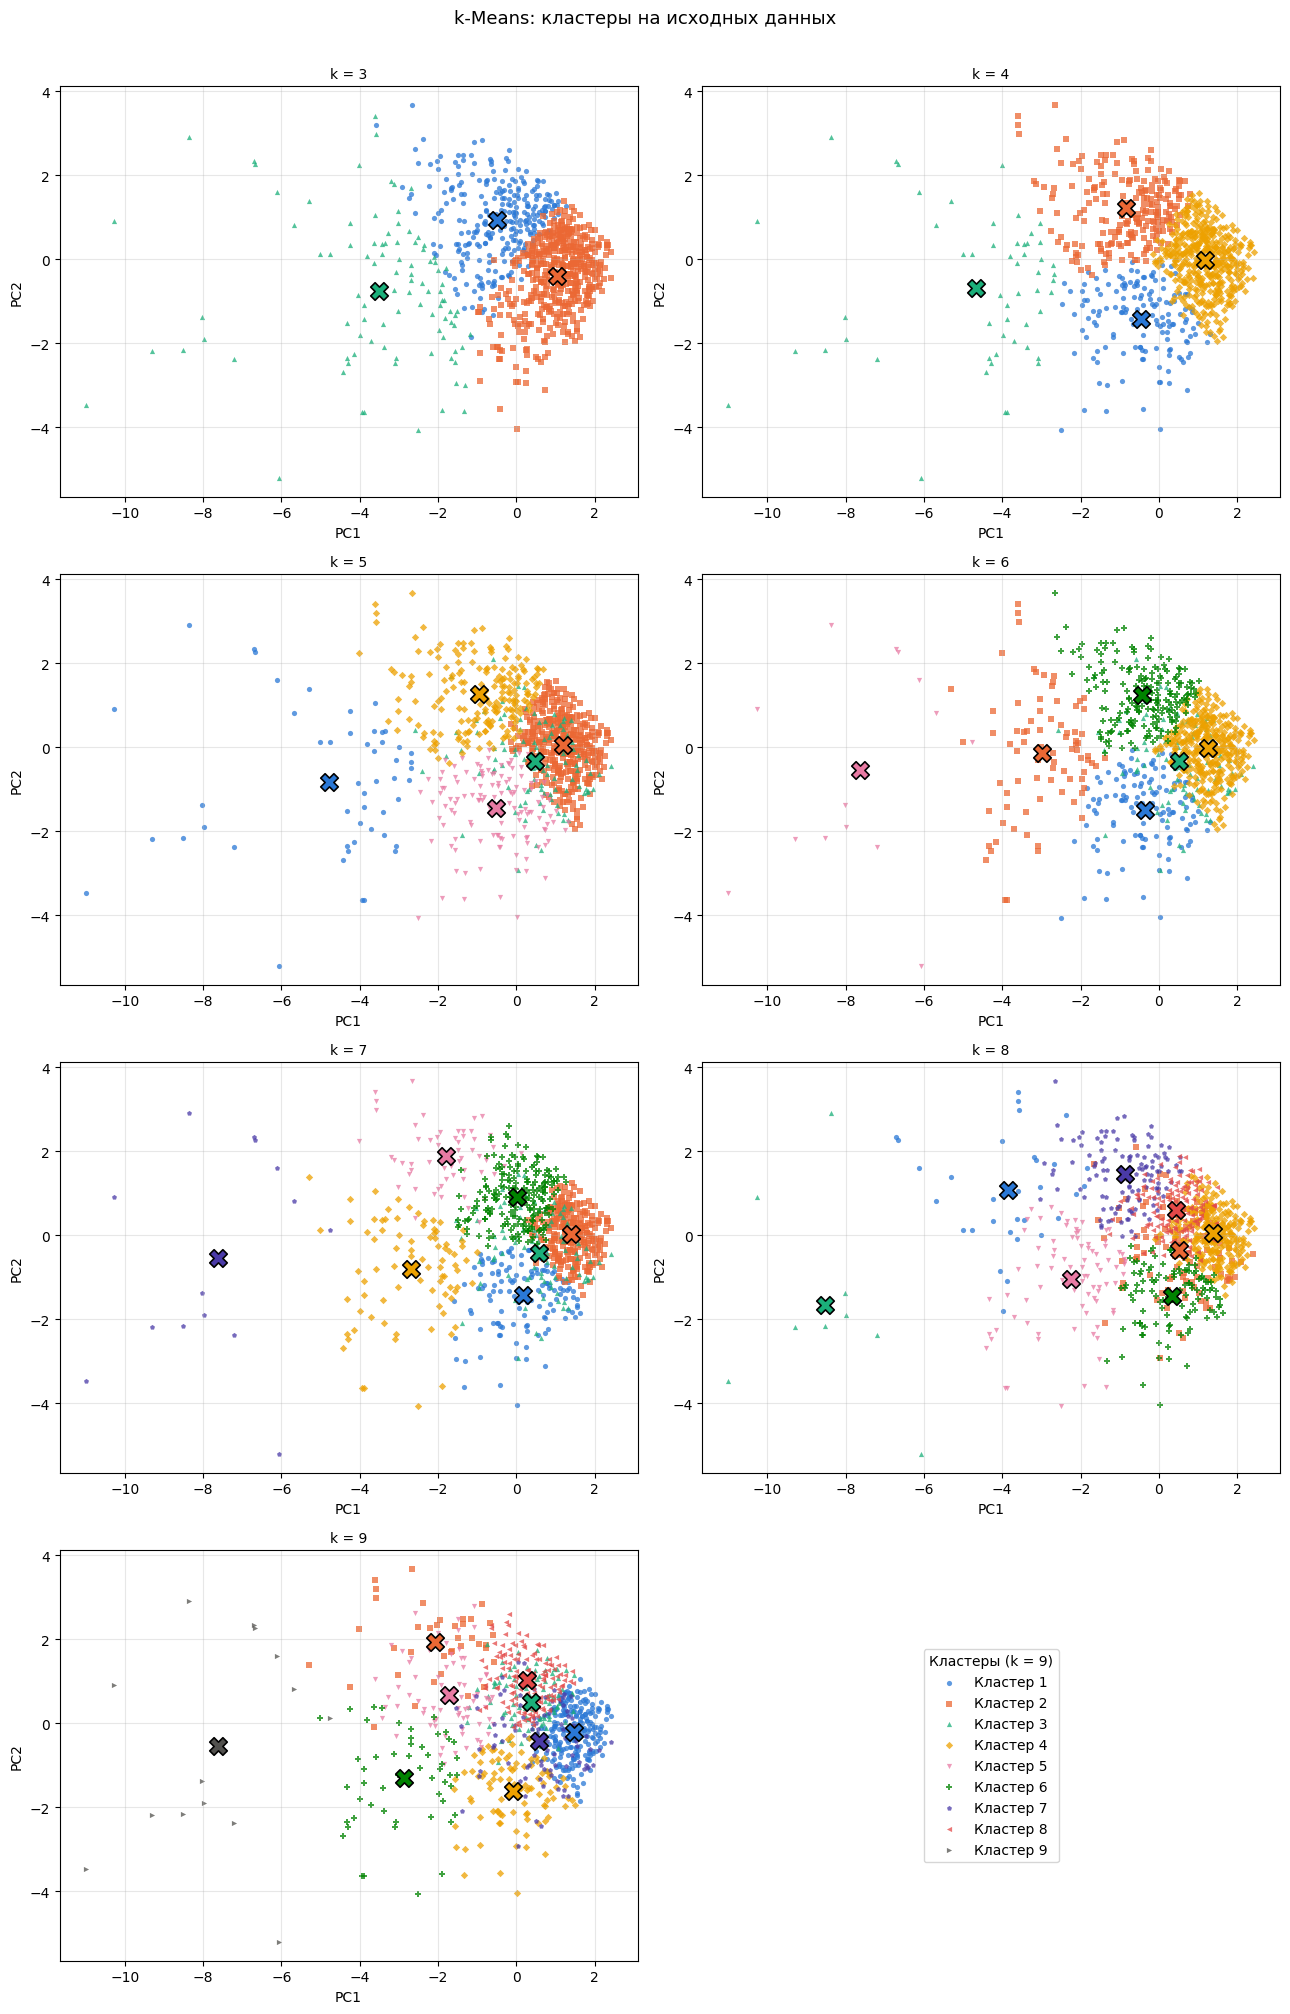

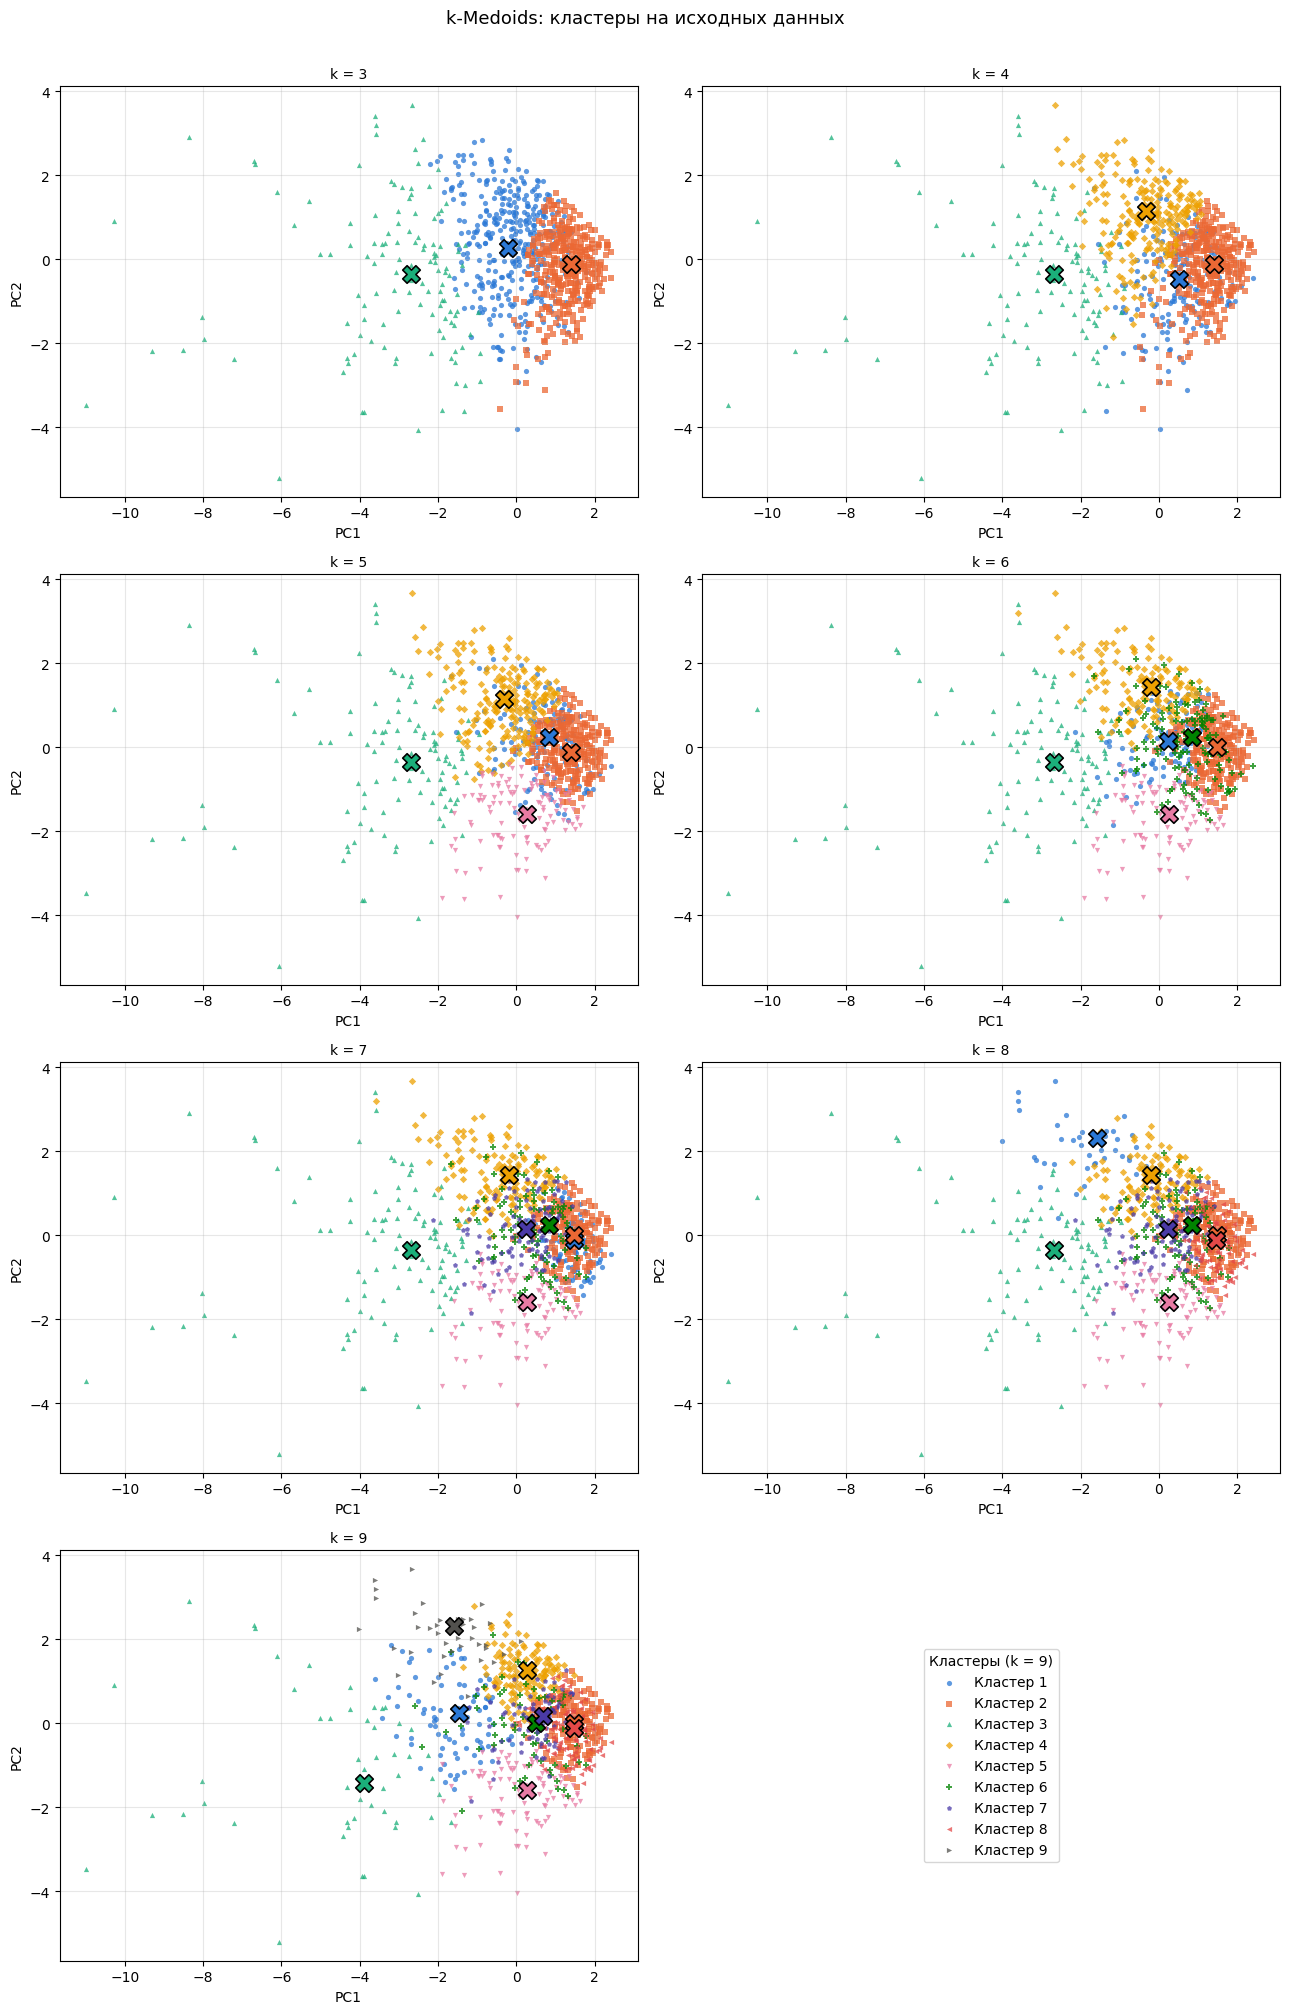

In [28]:
for alg, cls in ALGORITHMS.items():
    fig, axes = plt.subplots(4, 2, figsize=(13, 20))
    for ax, k in zip(axes.flat, K_RANGE):
        scatter(ax, *runs[alg, k], f'k = {k}')
    axes.flat[-1].axis('off')
    handles, labels = axes.flat[len(K_RANGE) - 1].get_legend_handles_labels()
    axes.flat[-1].legend(handles, labels, loc='center', title='Кластеры (k = 9)')
    plt.suptitle(f'{cls.NAME}: кластеры на исходных данных', y=1.005, fontsize=13)
    plt.tight_layout()
    fig.savefig(f'scatter_{alg}_clean.png', dpi=150, bbox_inches='tight')
    plt.show()

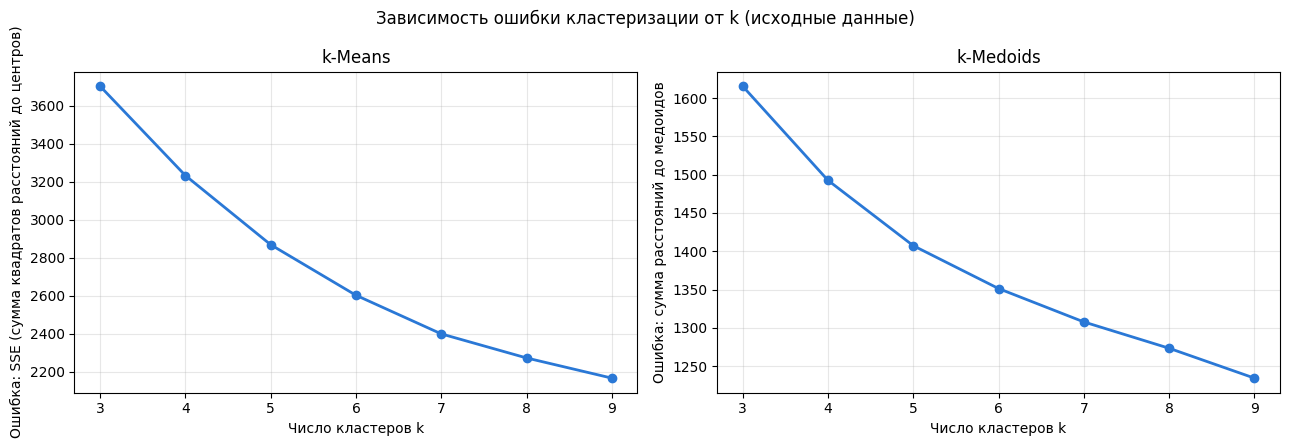

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (alg, cls) in zip(axes, ALGORITHMS.items()):
    grp = errors_clean[errors_clean['algorithm'] == cls.NAME]
    ax.plot(grp['k'], grp['error'], marker='o', lw=2, color=COLORS[0])
    ax.set_title(cls.NAME)
    ax.set_xlabel('Число кластеров k')
    ax.set_ylabel(f'Ошибка: {cls.ERROR}')
    ax.set_xticks(list(K_RANGE))
    ax.grid(alpha=0.3)
plt.suptitle('Зависимость ошибки кластеризации от k (исходные данные)')
plt.tight_layout()
fig.savefig('error_vs_k_clean.png', dpi=150, bbox_inches='tight')
plt.show()

In [30]:
def adjusted_rand(a, b):
    comb2 = lambda x: (x * (x - 1) / 2).sum()
    table = pd.crosstab(a, b).to_numpy()
    index, rows, cols = comb2(table), comb2(table.sum(1)), comb2(table.sum(0))
    expected = rows * cols / comb2(np.array([len(a)]))
    return (index - expected) / ((rows + cols) / 2 - expected)


NOISE = [0.01, 0.03, 0.05, 0.10]

rows = [{'algorithm': r['algorithm'], 'k': r['k'], 'noise': 0.0, 'error': r['error'], 'ari': 1.0}
        for r in errors_clean.to_dict('records')]
noisy_runs = {}
for alg, cls in ALGORITHMS.items():
    for frac in NOISE:
        for k in K_RANGE:
            points, centers, error, _ = cluster(data, alg, k, noise_frac=frac)
            noisy_runs[alg, frac, k] = points, centers
            clean = ~points['noisy'].to_numpy()
            ari = adjusted_rand(runs[alg, k][0]['cluster'].to_numpy()[clean], points['cluster'].to_numpy()[clean])
            rows.append({'algorithm': cls.NAME, 'k': k, 'noise': frac, 'error': error, 'ari': ari})
noisy_results = pd.DataFrame(rows)
noisy_results.pivot_table(index='k', columns=['algorithm', 'noise'], values='error')

algorithm    k-Means                                              k-Medoids  \
noise           0.00       0.01       0.03       0.05       0.10       0.00   
k                                                                             
3          3702.4198  3753.3683  3776.7991  3863.7292  4038.7361  1615.5180   
4          3232.7065  3294.3645  3353.1717  3424.1893  3618.6032  1492.6640   
5          2869.0195  2933.4786  2997.6915  3076.9119  3304.1947  1407.3627   
6          2603.2543  2677.1530  2730.0184  2835.2478  3110.6485  1351.4146   
7          2400.1935  2477.1925  2526.8853  2652.4495  2962.8483  1307.8534   
8          2273.6320  2348.0436  2411.6207  2523.4547  2819.7343  1273.4782   
9          2167.6040  2247.9911  2319.5769  2410.9888  2717.7193  1234.5071   

algorithm                                              
noise           0.01       0.03       0.05       0.10  
k                                                      
3          1614.9589  1613.5192  1624.1084  1611.5772  
4          1491.3718  1493.7654  1505.5559  1505.6485  
5          1408.6799  1416.3357  1424.6277  1427.9051  
6          1354.2002  1362.9594  1369.7467  1383.8909  
7          1310.2200  1320.2384  1326.2201  1350.4034  
8          1276.3893  1285.9102  1291.6360  1317.6443  
9          1237.6534  1245.5048  1254.5863  1290.6746

In [31]:
noisy_results.pivot_table(index='k', columns=['algorithm', 'noise'], values='ari')

algorithm k-Means                                 k-Medoids                  \
noise        0.00    0.01    0.03    0.05    0.10      0.00    0.01    0.03   
k                                                                             
3             1.0  0.8747  0.9890  0.9452  0.8111       1.0  0.9788  0.9913   
4             1.0  0.8376  0.8368  0.8194  0.9285       1.0  1.0000  0.9891   
5             1.0  0.9762  0.8722  0.9579  0.9061       1.0  1.0000  0.9901   
6             1.0  0.6823  0.7487  0.7170  0.8409       1.0  0.9943  0.9950   
7             1.0  0.9821  0.7858  0.8307  0.5133       1.0  0.9949  0.9281   
8             1.0  0.7786  0.6762  0.7738  0.6538       1.0  0.9949  0.9285   
9             1.0  0.6867  0.6021  0.6260  0.6268       1.0  0.9955  0.9834   

algorithm                  
noise        0.05    0.10  
k                          
3          0.8602  0.9812  
4          0.8874  0.9750  
5          0.8968  0.9678  
6          0.9895  0.9282  
7          0.9235  0.9458  
8          0.9212  0.9467  
9          0.9866  0.6864

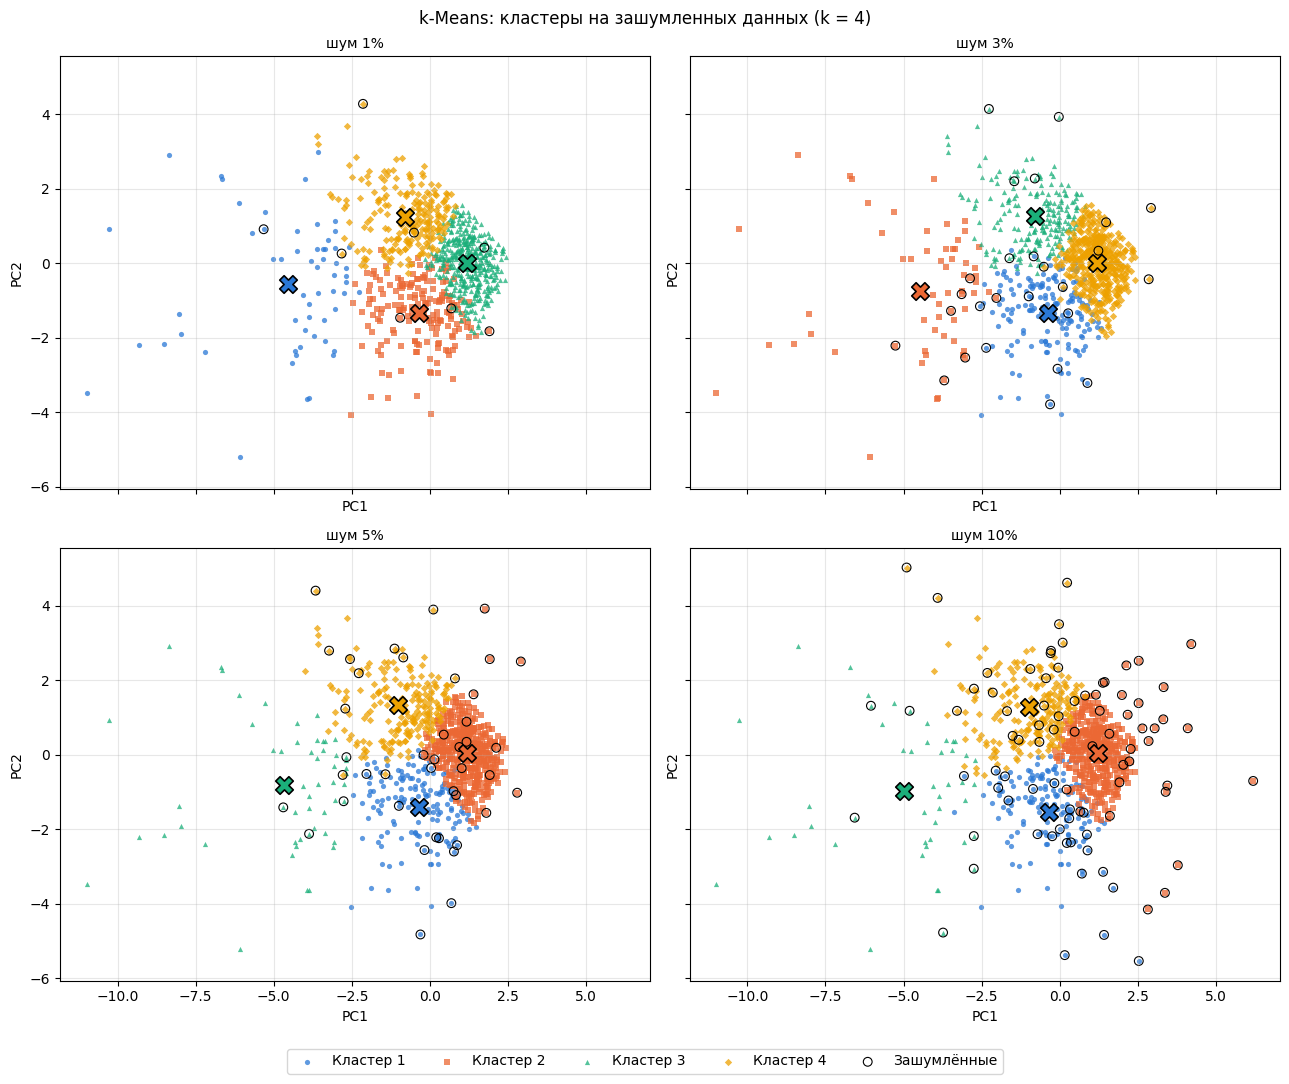

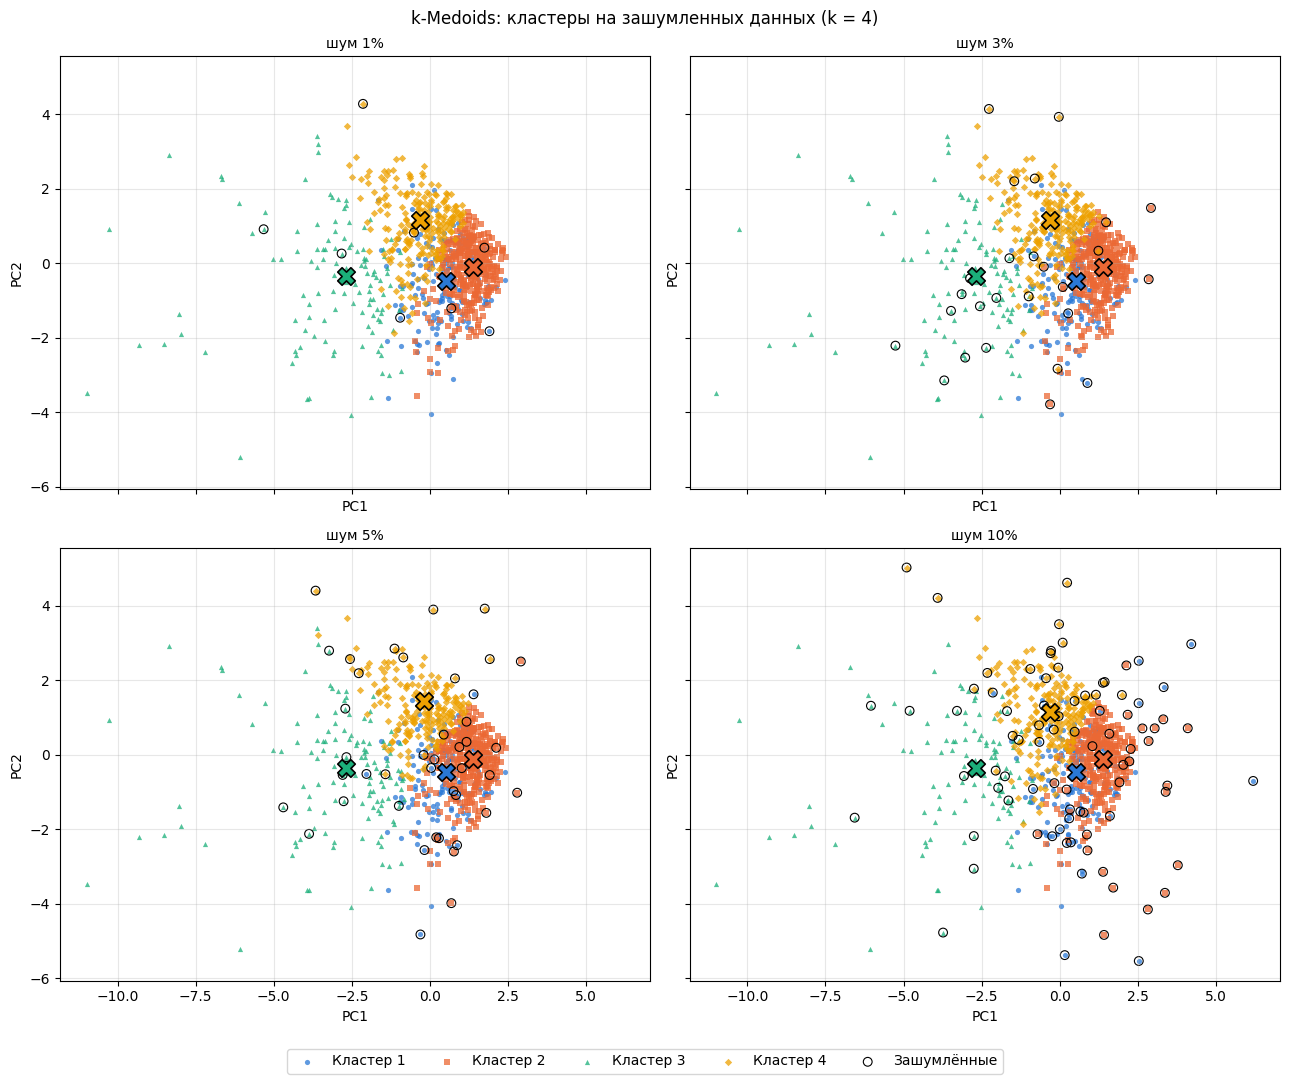

In [32]:
K_SHOW = 4

for alg, cls in ALGORITHMS.items():
    fig, axes = plt.subplots(2, 2, figsize=(13, 10.5), sharex=True, sharey=True)
    for ax, frac in zip(axes.flat, NOISE):
        scatter(ax, *noisy_runs[alg, frac, K_SHOW], f'шум {frac:.0%}')
    fig.legend(*axes.flat[-1].get_legend_handles_labels(), loc='lower center', ncol=K_SHOW + 1, bbox_to_anchor=(0.5, -0.04))
    plt.suptitle(f'{cls.NAME}: кластеры на зашумленных данных (k = {K_SHOW})')
    plt.tight_layout()
    fig.savefig(f'scatter_{alg}_noise.png', dpi=150, bbox_inches='tight')
    plt.show()

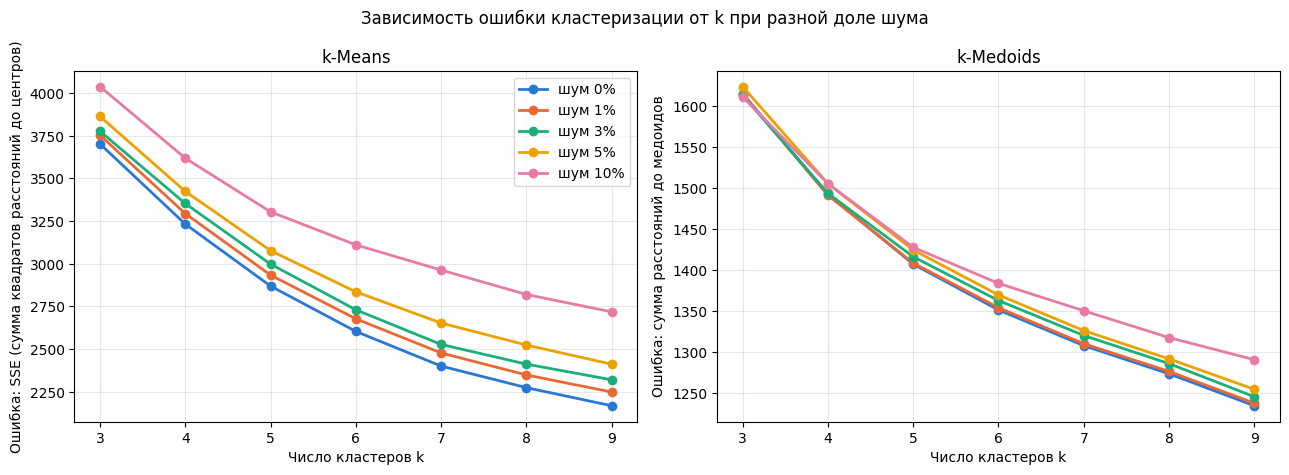

In [33]:
NOISE_COLORS = dict(zip([0.0] + NOISE, COLORS))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (alg, cls) in zip(axes, ALGORITHMS.items()):
    for frac, grp in noisy_results[noisy_results['algorithm'] == cls.NAME].groupby('noise'):
        ax.plot(grp['k'], grp['error'], marker='o', lw=2, color=NOISE_COLORS[frac], label=f'шум {frac:.0%}')
    ax.set_title(cls.NAME)
    ax.set_xlabel('Число кластеров k')
    ax.set_ylabel(f'Ошибка: {cls.ERROR}')
    ax.set_xticks(list(K_RANGE))
    ax.grid(alpha=0.3)
axes[0].legend()
plt.suptitle('Зависимость ошибки кластеризации от k при разной доле шума')
plt.tight_layout()
fig.savefig('error_vs_k_noise.png', dpi=150, bbox_inches='tight')
plt.show()

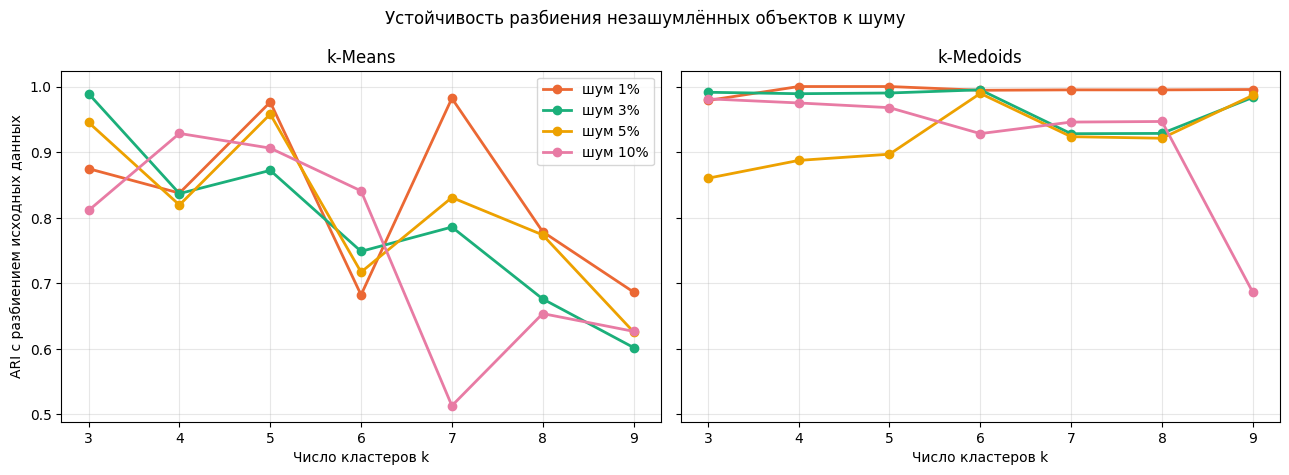

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, (alg, cls) in zip(axes, ALGORITHMS.items()):
    for frac, grp in noisy_results[(noisy_results['algorithm'] == cls.NAME) & (noisy_results['noise'] > 0)].groupby('noise'):
        ax.plot(grp['k'], grp['ari'], marker='o', lw=2, color=NOISE_COLORS[frac], label=f'шум {frac:.0%}')
    ax.set_title(cls.NAME)
    ax.set_xlabel('Число кластеров k')
    ax.set_xticks(list(K_RANGE))
    ax.grid(alpha=0.3)
axes[0].set_ylabel('ARI с разбиением исходных данных')
axes[0].legend()
plt.suptitle('Устойчивость разбиения незашумлённых объектов к шуму')
plt.tight_layout()
fig.savefig('ari_vs_k_noise.png', dpi=150, bbox_inches='tight')
plt.show()